In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm import tqdm

sys.path.append('../..')
sys.path.append('../../Model')
from Network.index import ModelNetwork
from Dataset.index import setFolder

# DADO REAL PSEUDO-ROTULADO (IRACEMA)

- Tiles 128³ do bloco Iracema, que não tem anotação, recebem como rótulo a **probabilidade média das redes de `TEACHERS`**: o consenso de arquiteturas diferentes. No Marlim esse consenso é mais preciso que qualquer uma delas sozinha — MACNN + NRU + `dbrnet` dão F1 de sticks 0,372 contra 0,327 da melhor, melhor nos 4 patches, porque o falso positivo de cada rede vem do que ela aprendeu de errado no sintético e a falha real aparece em todas
- Grava `images/` (o tile como está, já em `[0, 1]` como os do Marlim), `probs/` (a média, float16) e `masks/` (0 onde a média fica abaixo de `LO`, 1 a partir de `HI`, 255 no meio) e o `DataBase.csv`
- Só entram tiles com sísmica viva: faixa `LAYERS` de tiles em z (abaixo da água e acima da zona morta) e desvio acima de `MIN_STD`
- Quem usa é o `Model/4 - SelfTrain.ipynb`; o `1 - Model` não lê este dataset. Nenhum rótulo do Marlim entra em nada aqui

In [2]:
TEACHERS = ['../../Documents/Backups/Multiscale/model_5', '../../Documents/Backups/Multiscale/model_7', '../../Documents/Backups/Artigo/model_5']
SOURCE   = '../../Iracema/files'
N_TILES  = 400
LAYERS   = (7, 22)      # ÍNDICES h DOS TILES EM z: z ~450-1440, ENTRE A ÁGUA E A ZONA MORTA
MIN_STD  = 0.06         # TILE MAIS APAGADO QUE ISSO É ÁGUA OU ZONA MORTA
HI, LO   = 0.5, 0.1     # LIMIARES DA MÁSCARA DURA (O SelfTrain USA A MÉDIA EM probs/ POR PADRÃO)
SEED     = 7

### TILES
- Sorteio na faixa `LAYERS`, descartando os apagados, até juntar `N_TILES`

In [3]:
meta  = json.load(open(f'{SOURCE}/patch_metadata.json'))
shape = (meta['patch_size'],) * 3
names = [name for name in meta['patch_files'] if LAYERS[0] <= int(name.split('_h')[1][:3]) <= LAYERS[1]]
np.random.default_rng(SEED).shuffle(names)

tiles, images = [], []
for name in names:
    tile = np.fromfile(f'{SOURCE}/patches/{name}', dtype=np.float32).reshape(shape)

    if tile.std() > MIN_STD:
        tiles.append(name)
        images.append(tile)

    if len(tiles) == N_TILES:
        break

print(f'{len(tiles)} tiles vivos de {len(names)} candidatos, desvio médio {np.mean([t.std() for t in images]):.3f}')

400 tiles vivos de 19264 candidatos, desvio médio 0.160


### PROFESSORES
- Cada rede de `TEACHERS` prediz os tiles inteiros (128³, a janela em que todas treinaram), uma de cada vez na GPU, e a média vai acumulando

In [4]:
def loadTeacher(path):
    info    = json.load(open(f'{path}/info.json'))
    network = ModelNetwork(**info['model'])
    network.model.load_state_dict(torch.load(f'{path}/model.pth', map_location=network.device, weights_only=False)['model'])
    return network.model.eval(), network.device


probs = np.zeros((len(tiles), *shape), np.float16)

for path in TEACHERS:
    model, device = loadTeacher(path)

    with torch.no_grad():
        for i, tile in enumerate(tqdm(images, desc=os.path.basename(path))):
            prob     = torch.sigmoid(model(torch.from_numpy(tile)[None, None].to(device)))[0, 0].float().cpu().numpy()
            probs[i] = probs[i] + (prob / len(TEACHERS)).astype(np.float16)

    del model
    torch.cuda.empty_cache()

print(f'média >= {HI}: {(probs >= HI).mean():.4f} | abaixo de {LO}: {(probs < LO).mean():.4f}')

model_5:   0%|          | 0/400 [00:00<?, ?it/s]

model_5:   0%|          | 1/400 [00:02<14:57,  2.25s/it]

model_5:   0%|          | 2/400 [00:04<14:20,  2.16s/it]

model_5:   1%|          | 3/400 [00:06<14:01,  2.12s/it]

model_5:   1%|          | 4/400 [00:08<13:55,  2.11s/it]

...

model_5: 100%|█████████▉| 398/400 [13:19<00:04,  2.06s/it]

model_5: 100%|█████████▉| 399/400 [13:21<00:02,  2.05s/it]

model_5: 100%|██████████| 400/400 [13:23<00:00,  2.05s/it]

model_5: 100%|██████████| 400/400 [13:23<00:00,  2.01s/it]

média >= 0.5: 0.0145 | abaixo de 0.1: 0.9033


### GRAVAÇÃO

In [5]:
for folder in ('images', 'probs', 'masks'):
    setFolder(folder)

rows = []
for name, tile, prob in zip(tiles, images, probs):
    stem = name.replace('.dat', '')
    mask = np.full(shape, 255, np.uint8)
    mask[prob >= HI] = 1
    mask[prob < LO]  = 0

    np.save(f'images/{stem}.npy', tile)
    np.save(f'probs/{stem}.npy', prob)
    np.save(f'masks/{stem}.npy', mask)

    rows.append({'id': f'{stem}.npy', 'img_min': tile.min(), 'img_max': tile.max(), 'img_mean': tile.mean(), 'img_std': tile.std(),
                 'falha': (mask == 1).mean(), 'ignorado': (mask == 255).mean(), 'shape': shape,
                 'img_path': os.path.abspath(f'images/{stem}.npy'), 'mask_path': os.path.abspath(f'masks/{stem}.npy'), 'prob_path': os.path.abspath(f'probs/{stem}.npy'),
                 'scaling': 'bloco'})

df = pd.DataFrame(rows)
df.to_csv('DataBase.csv', index=None)
df.describe().round(4)

,img_min,img_max,img_mean,img_std,falha,ignorado
count,400.0000,400.0000,400.0000,400.0000,400.0000,400.0000
mean,0.0447,0.9725,0.4949,0.1601,0.0145,0.0822
std,0.0730,0.0581,0.0043,0.0775,0.0139,0.0405
min,0.0000,0.7015,0.4816,0.0602,0.0000,0.0104
25%,0.0000,0.9862,0.4928,0.0894,0.0044,0.0484
50%,0.0000,1.0000,0.4953,0.1480,0.0098,0.0755
75%,0.0885,1.0000,0.4969,0.2180,0.0207,0.1096
max,0.2822,1.0000,0.5102,0.3470,0.0660,0.1986


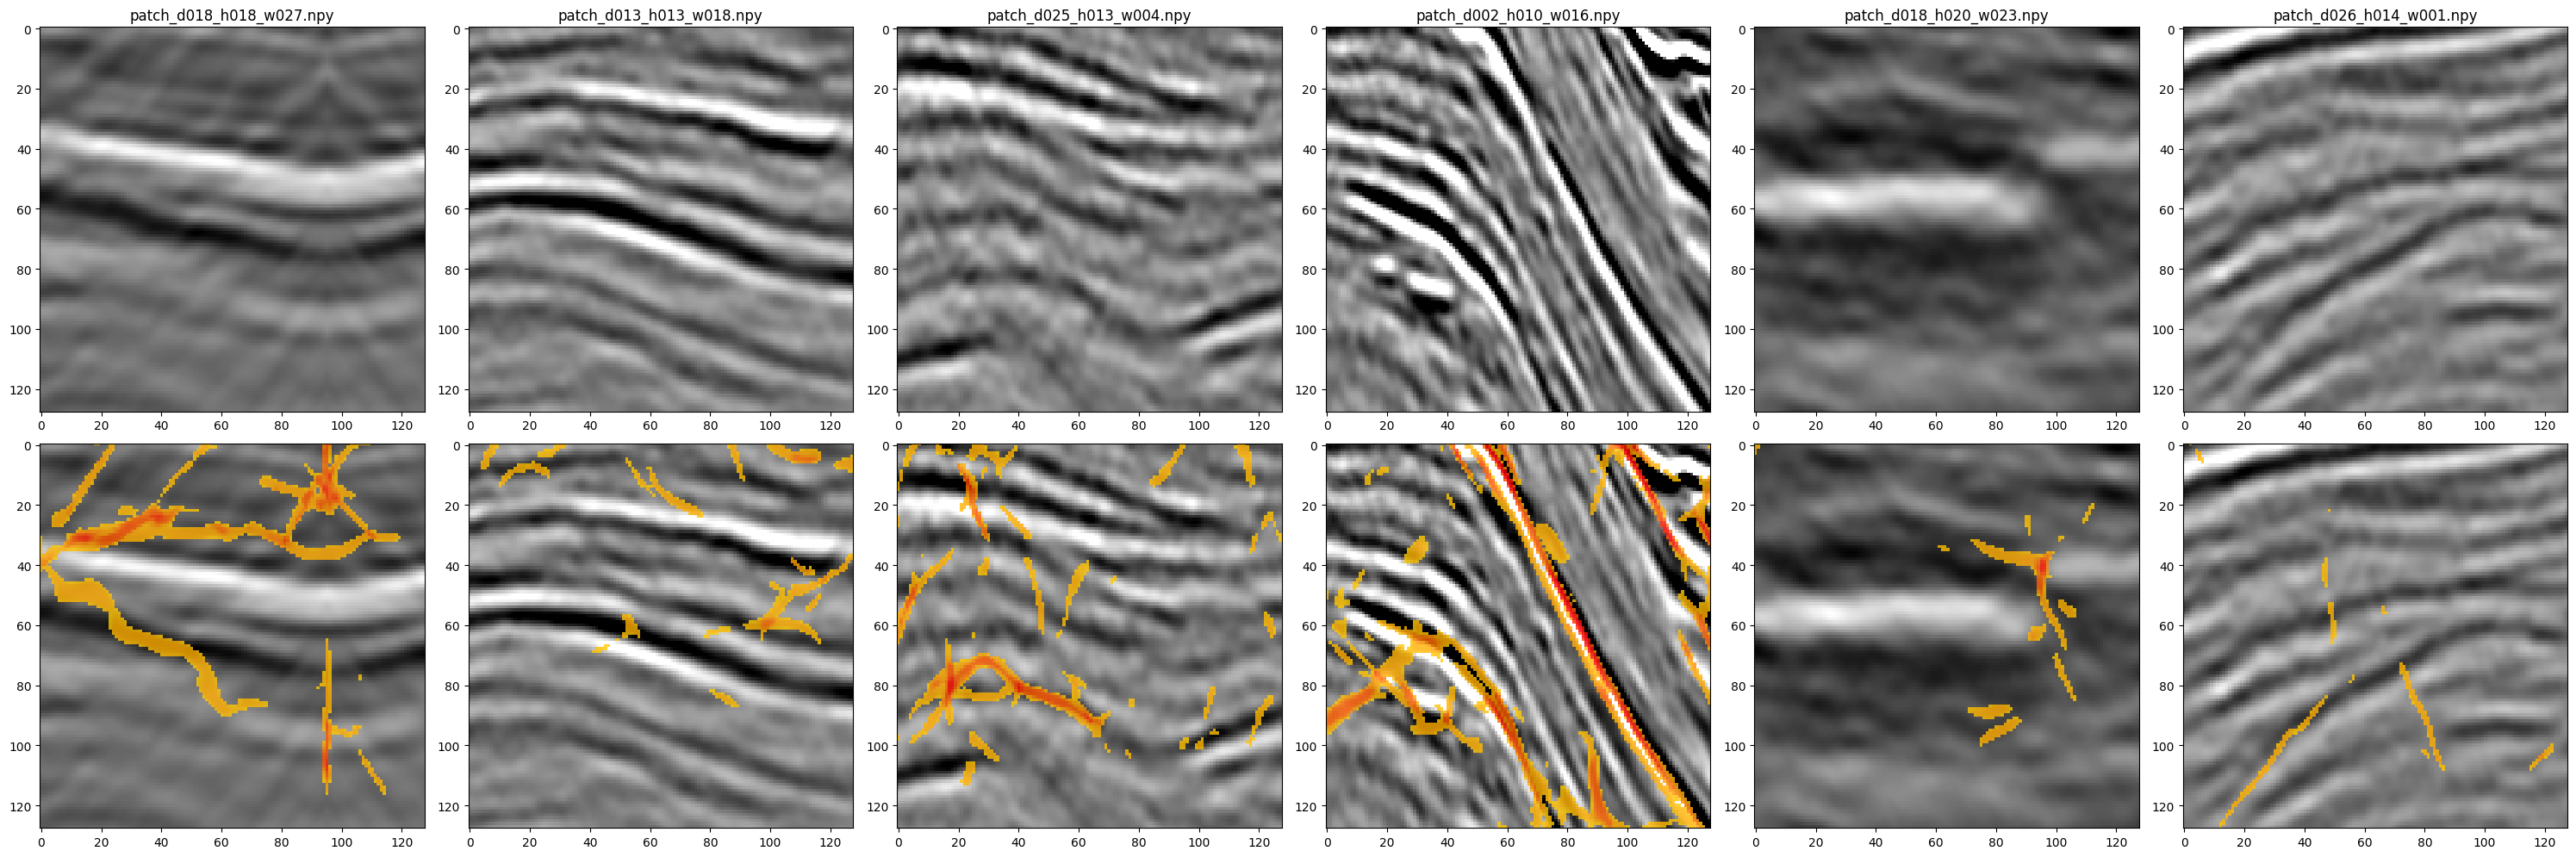

In [6]:
fig, axes = plt.subplots(2, 6, figsize=(30, 10))

for column, index in enumerate(np.linspace(0, len(df) - 1, 6).astype(int)):
    tile, prob = np.load(df.img_path[index]), np.load(df.prob_path[index]).astype(np.float32)
    axes[0, column].imshow(tile[64], cmap='gray')
    axes[0, column].set_title(df.id[index])
    axes[1, column].imshow(tile[64], cmap='gray')
    axes[1, column].imshow(np.ma.masked_less(prob[64], 0.2), cmap='autumn_r', vmin=0, vmax=1, alpha=0.8)

plt.tight_layout()
plt.show()